# 2. Base model: Minuit and MCMC (η = 1/12, blob frame)

    The fits take ~15 min each. With `RUN_FIT = False` and `RUN_MCMC = False` the notebook loads the saved
    results from `results/` and only remakes the tables and figures.

In [1]:
%run mg3_setup.py

JetSeT version: 1.3.0
---> excluding  data_set/s ['-1']
filter -1 46
current datasets
dataset 0.0
---> data sets left after filtering None
---> data len after filtering=46
points: 46  (detections 40, UL 6), in fit range 38, in 3-79 keV 11


In [2]:
RUN_FIT = False      # True: redo the Minuit fit (~15 min)
RUN_MCMC = False     # True: redo the MCMC (~15 min)

## Minuit

===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
adding par: z_cosm to  z_cosm
===> setting C threads to 8
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to 

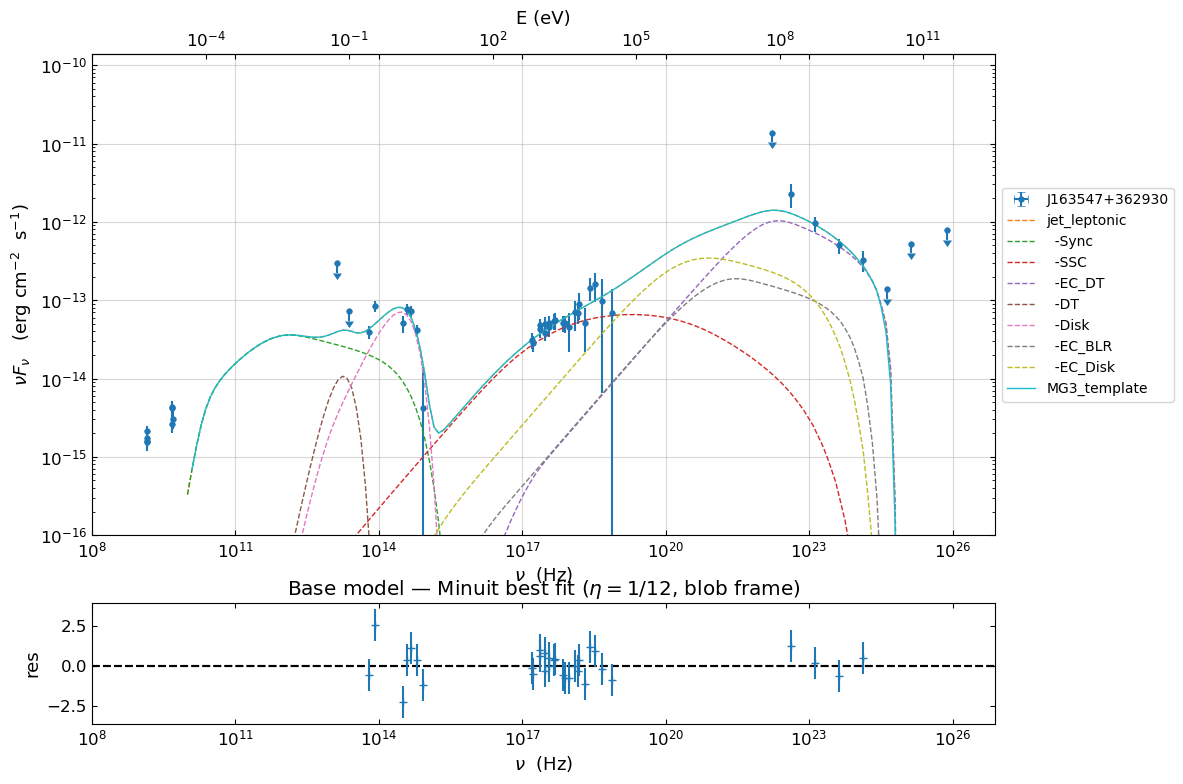

NuSTAR band: model nuFnu slope = +0.36  ->  Gamma_X = 1.64
             data: Gamma_X = 0.94 +- 0.34 (XSPEC), 1.38 (SED points)
   at 10 keV: SSC 64%, EC_DT 4%, EC_BLR 5%, EC_Disk 27%
   at 40 keV: SSC 44%, EC_DT 7%, EC_BLR 7%, EC_Disk 42%


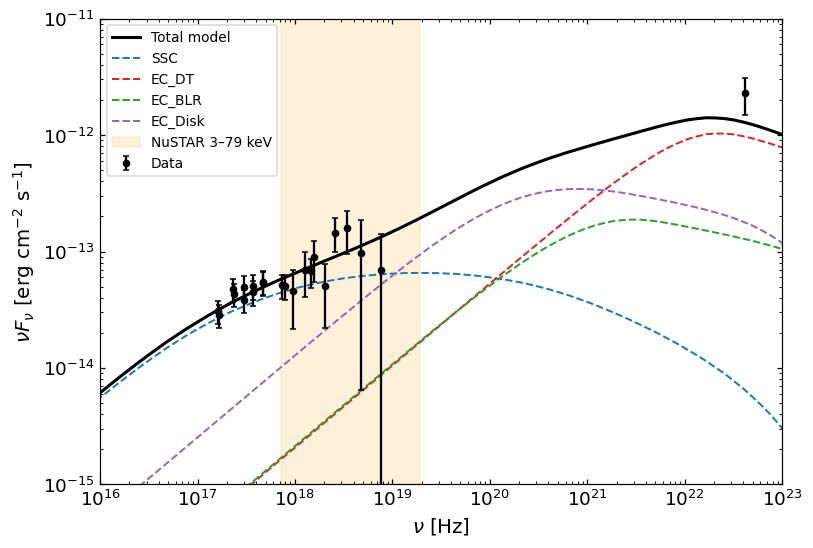

In [3]:
from jetset.minimizer import FitResults

model_tag = 'base_eta0p083'        # all files of the base model use this tag

# 1. load the template and set the frame and accretion efficiency
fit_model = FitModel.load_model(TEMPLATE_FILE)
fit_model.jet_leptonic.set_external_field_transf(EXT_FIELD_FRAME)
fit_model.jet_leptonic.set_num_c_threads(8)

fit_model.jet_leptonic.parameters.accr_eff.val = ETA_BASE

# 2. starting values (previous blob-frame solution for eta = 0.083)
start_values = {
    # electron distribution
    'gmin':        2.100764,      # fixed
    'gmax':        1.853e4,       # fixed
    'p':           1.590080,      # fixed (low-energy slope)
    'p_1':         3.40,
    'gamma_break': 928.0,
    'N':           1671.0,
    # emitting region
    'B':           0.0578,
    'BulkFactor':  17.4,
    'theta':       3.0,           # fixed (viewing angle)
    'R_H':         1.61e18,       # sets R through R = R_H tan(theta_open)
    # central engine
    'M_BH':        1.89e9,
    'L_Disk':      1.85e46,
    'R_inner_Sw':  7.73,
    'R_ext_Sw':    3944.0,
    'T_DT':        900.0,
}
for pname, val in start_values.items():
    fit_model.jet_leptonic.parameters.get_par_by_name(pname).val = val

# 3. frozen and free parameters
freeze_list = ['theta', 'theta_open', 'z_cosm', 'tau_DT', 'tau_BLR',
               'gmin', 'gmax', 'p', 'accr_eff', 'NH_cold_to_rel_e']

free_list = ['B', 'BulkFactor', 'N', 'gamma_break', 'p_1',      # jet
             'M_BH', 'L_Disk', 'R_inner_Sw', 'R_ext_Sw',        # disc
             'T_DT', 'R_H']                                     # torus / blob position

for pname in freeze_list:
    fit_model.jet_leptonic.parameters.get_par_by_name(pname).frozen = True
for pname in free_list:
    fit_model.jet_leptonic.parameters.get_par_by_name(pname).frozen = False

# 4. bounds (wide and physically motivated; also used as MCMC priors)
bounds = {
    'B':            [0.01,   0.20],     # G
    'BulkFactor':   [8.0,    30.0],
    'N':            [300.0,  8000.0],   # cm^-3
    'gamma_break':  [300.0,  4000.0],
    'p_1':          [2.40,   4.50],
    'M_BH':         [3.0e8,  8.0e9],    # M_sun
    'L_Disk':       [0.5e46, 6.0e46],   # erg/s
    'R_inner_Sw':   [2.07,   20.0],     # Schwarzschild radii; >= ISCO for eta = 1/12
    'R_ext_Sw':     [300.0,  2.0e4],    # Schwarzschild radii
    'T_DT':         [300.0,  1500.0],   # K; dust sublimates at ~1500 K
    'R_H':          [5.0e17, 8.0e18],   # cm; between the BLR and the torus
}
for pname, (lo, hi) in bounds.items():
    par = fit_model.jet_leptonic.parameters.get_par_by_name(pname)
    par.val_min = lo
    par.val_max = hi
    par.fit_range = [lo, hi]

# 5. Minuit fit
if RUN_FIT:
    fit_model.eval()
    model_minimizer = ModelMinimizer('minuit')
    best_fit = model_minimizer.fit(fit_model, sed_data,
                                   NU_FIT_MIN, NU_FIT_MAX,
                                   fitname=model_tag,
                                   repeat=3,
                                   use_UL=True)
    fit_model.eval()

    # 6. save everything needed by the MCMC below
    best_fit.save_report(f'Report_Minuit_{model_tag}.pkl')
    fit_model.save_model(f'Model_Minuit_{model_tag}.pkl')
    model_minimizer.save_model(f'Minimizer_{model_tag}.pkl')
    with open(f'bounds_{model_tag}.json', 'w') as f:
        json.dump(bounds, f, indent=2)
else:
    fit_model = FitModel.load_model(f'Model_Minuit_{model_tag}.pkl')
    fit_model.jet_leptonic.set_external_field_transf(EXT_FIELD_FRAME)
    fit_model.eval()
    best_fit = FitResults.load_report(f'Report_Minuit_{model_tag}.pkl')

# 7. results
jet = fit_model.jet_leptonic
print(f"\nchi2 = {best_fit.chisq:.2f} / {best_fit.dof} dof  (reduced {best_fit.chisq_red:.3f})")
print(f"detections only: {best_fit.chisq_no_UL:.2f} / {best_fit.dof_no_UL}")
print("frame:", jet.get_external_field_transf())

print("\nBest-fit parameters:")
for pname in free_list:
    val = jet.parameters.get_par_by_name(pname).val
    lo, hi = bounds[pname]
    flag = '  <-- AT BOUND' if (np.isclose(val, lo, rtol=0.01) or np.isclose(val, hi, rtol=0.01)) else ''
    print(f"   {pname:>12s} = {val:.4e}{flag}")

L_disk, M_bh = jet.parameters.L_Disk.val, jet.parameters.M_BH.val
print("\nDerived:")
print(f"   lambda = L_disc/L_Edd = {L_disk / (1.26e38 * M_bh):.3f}")
print(f"   R_BLR_in = {jet.parameters.R_BLR_in.val:.3e} cm,  R_DT = {jet.parameters.R_DT.val:.3e} cm")
print(f"   R_H / R_BLR_out = {jet.parameters.R_H.val / jet.parameters.R_BLR_out.val:.2f},"
      f"  R_H / R_DT = {jet.parameters.R_H.val / jet.parameters.R_DT.val:.3f}")

# SED with all components
p = fit_model.plot_model(sed_data=sed_data)
p.setlim(y_min=1e-16, x_min=1e8)
plt.title(r'Base model — Minuit best fit ($\eta = 1/12$, blob frame)')
plt.savefig(os.path.join(FIG_DIR, f'SED_Minuit_{model_tag}.png'))
plt.show()

# 8. NuSTAR band - model slope and SSC / EC contributions
jet = fit_model.jet_leptonic
jet.eval()                                     # fills the individual component spectra
fit_model.eval()

keV = 2.418e17                                 # Hz per keV
nu_lo, nu_hi = 3 * keV, 79 * keV

nu  = fit_model.SED.nu.value
fnu = fit_model.SED.nuFnu.value
band = (nu > nu_lo) & (nu < nu_hi)
slope = np.polyfit(np.log10(nu[band]), np.log10(fnu[band]), 1)[0]
print(f"NuSTAR band: model nuFnu slope = {slope:+.2f}  ->  Gamma_X = {2 - slope:.2f}")
print( "             data: Gamma_X = 0.94 +- 0.34 (XSPEC), 1.38 (SED points)")

components = ['SSC', 'EC_DT', 'EC_BLR', 'EC_Disk']
for E in [10, 40]:
    total = np.interp(np.log10(E * keV), np.log10(nu), fnu)
    shares = []
    for comp in components:
        c = jet.get_spectral_component_by_name(comp).SED
        if c.nu is None:                       # component not computed
            shares.append(f"{comp} n/a")
            continue
        f_c = np.interp(np.log10(E * keV), np.log10(c.nu.value), np.clip(c.nuFnu.value, 1e-40, None))
        shares.append(f"{comp} {100 * f_c / total:.0f}%")
    print(f"   at {E:2d} keV: " + ", ".join(shares))

# zoom on the X-ray band
nu_d  = np.array(sed_data.table['nu_data'])
fl_d  = np.array(sed_data.table['nuFnu_data'])
err_d = np.array(sed_data.table['dnuFnu_data'])
det   = ~np.array(sed_data.table['UL'], dtype=bool)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.loglog(nu, fnu, 'k-', lw=2, label='Total model')
for comp, col in zip(components, ['tab:blue', 'tab:red', 'tab:green', 'tab:purple']):
    c = jet.get_spectral_component_by_name(comp).SED
    if c.nu is not None:
        ax.loglog(c.nu.value, c.nuFnu.value, '--', color=col, lw=1.3, label=comp)
ax.errorbar(nu_d[det], fl_d[det], yerr=err_d[det], fmt='o', color='k', ms=4, capsize=2, label='Data')
ax.axvspan(nu_lo, nu_hi, color='orange', alpha=0.15, label='NuSTAR 3–79 keV')
ax.set_xlim(1e16, 1e23); ax.set_ylim(1e-15, 1e-11)
ax.set_xlabel(r'$\nu$ [Hz]'); ax.set_ylabel(r'$\nu F_\nu$ [erg cm$^{-2}$ s$^{-1}$]')
ax.legend(fontsize=9)
plt.savefig(os.path.join(FIG_DIR, f'NuSTAR_band_{model_tag}.png'))
plt.show()

## MCMC
Flat priors inside the Minuit bounds.

===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
adding par: z_cosm to  z_cosm
===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in

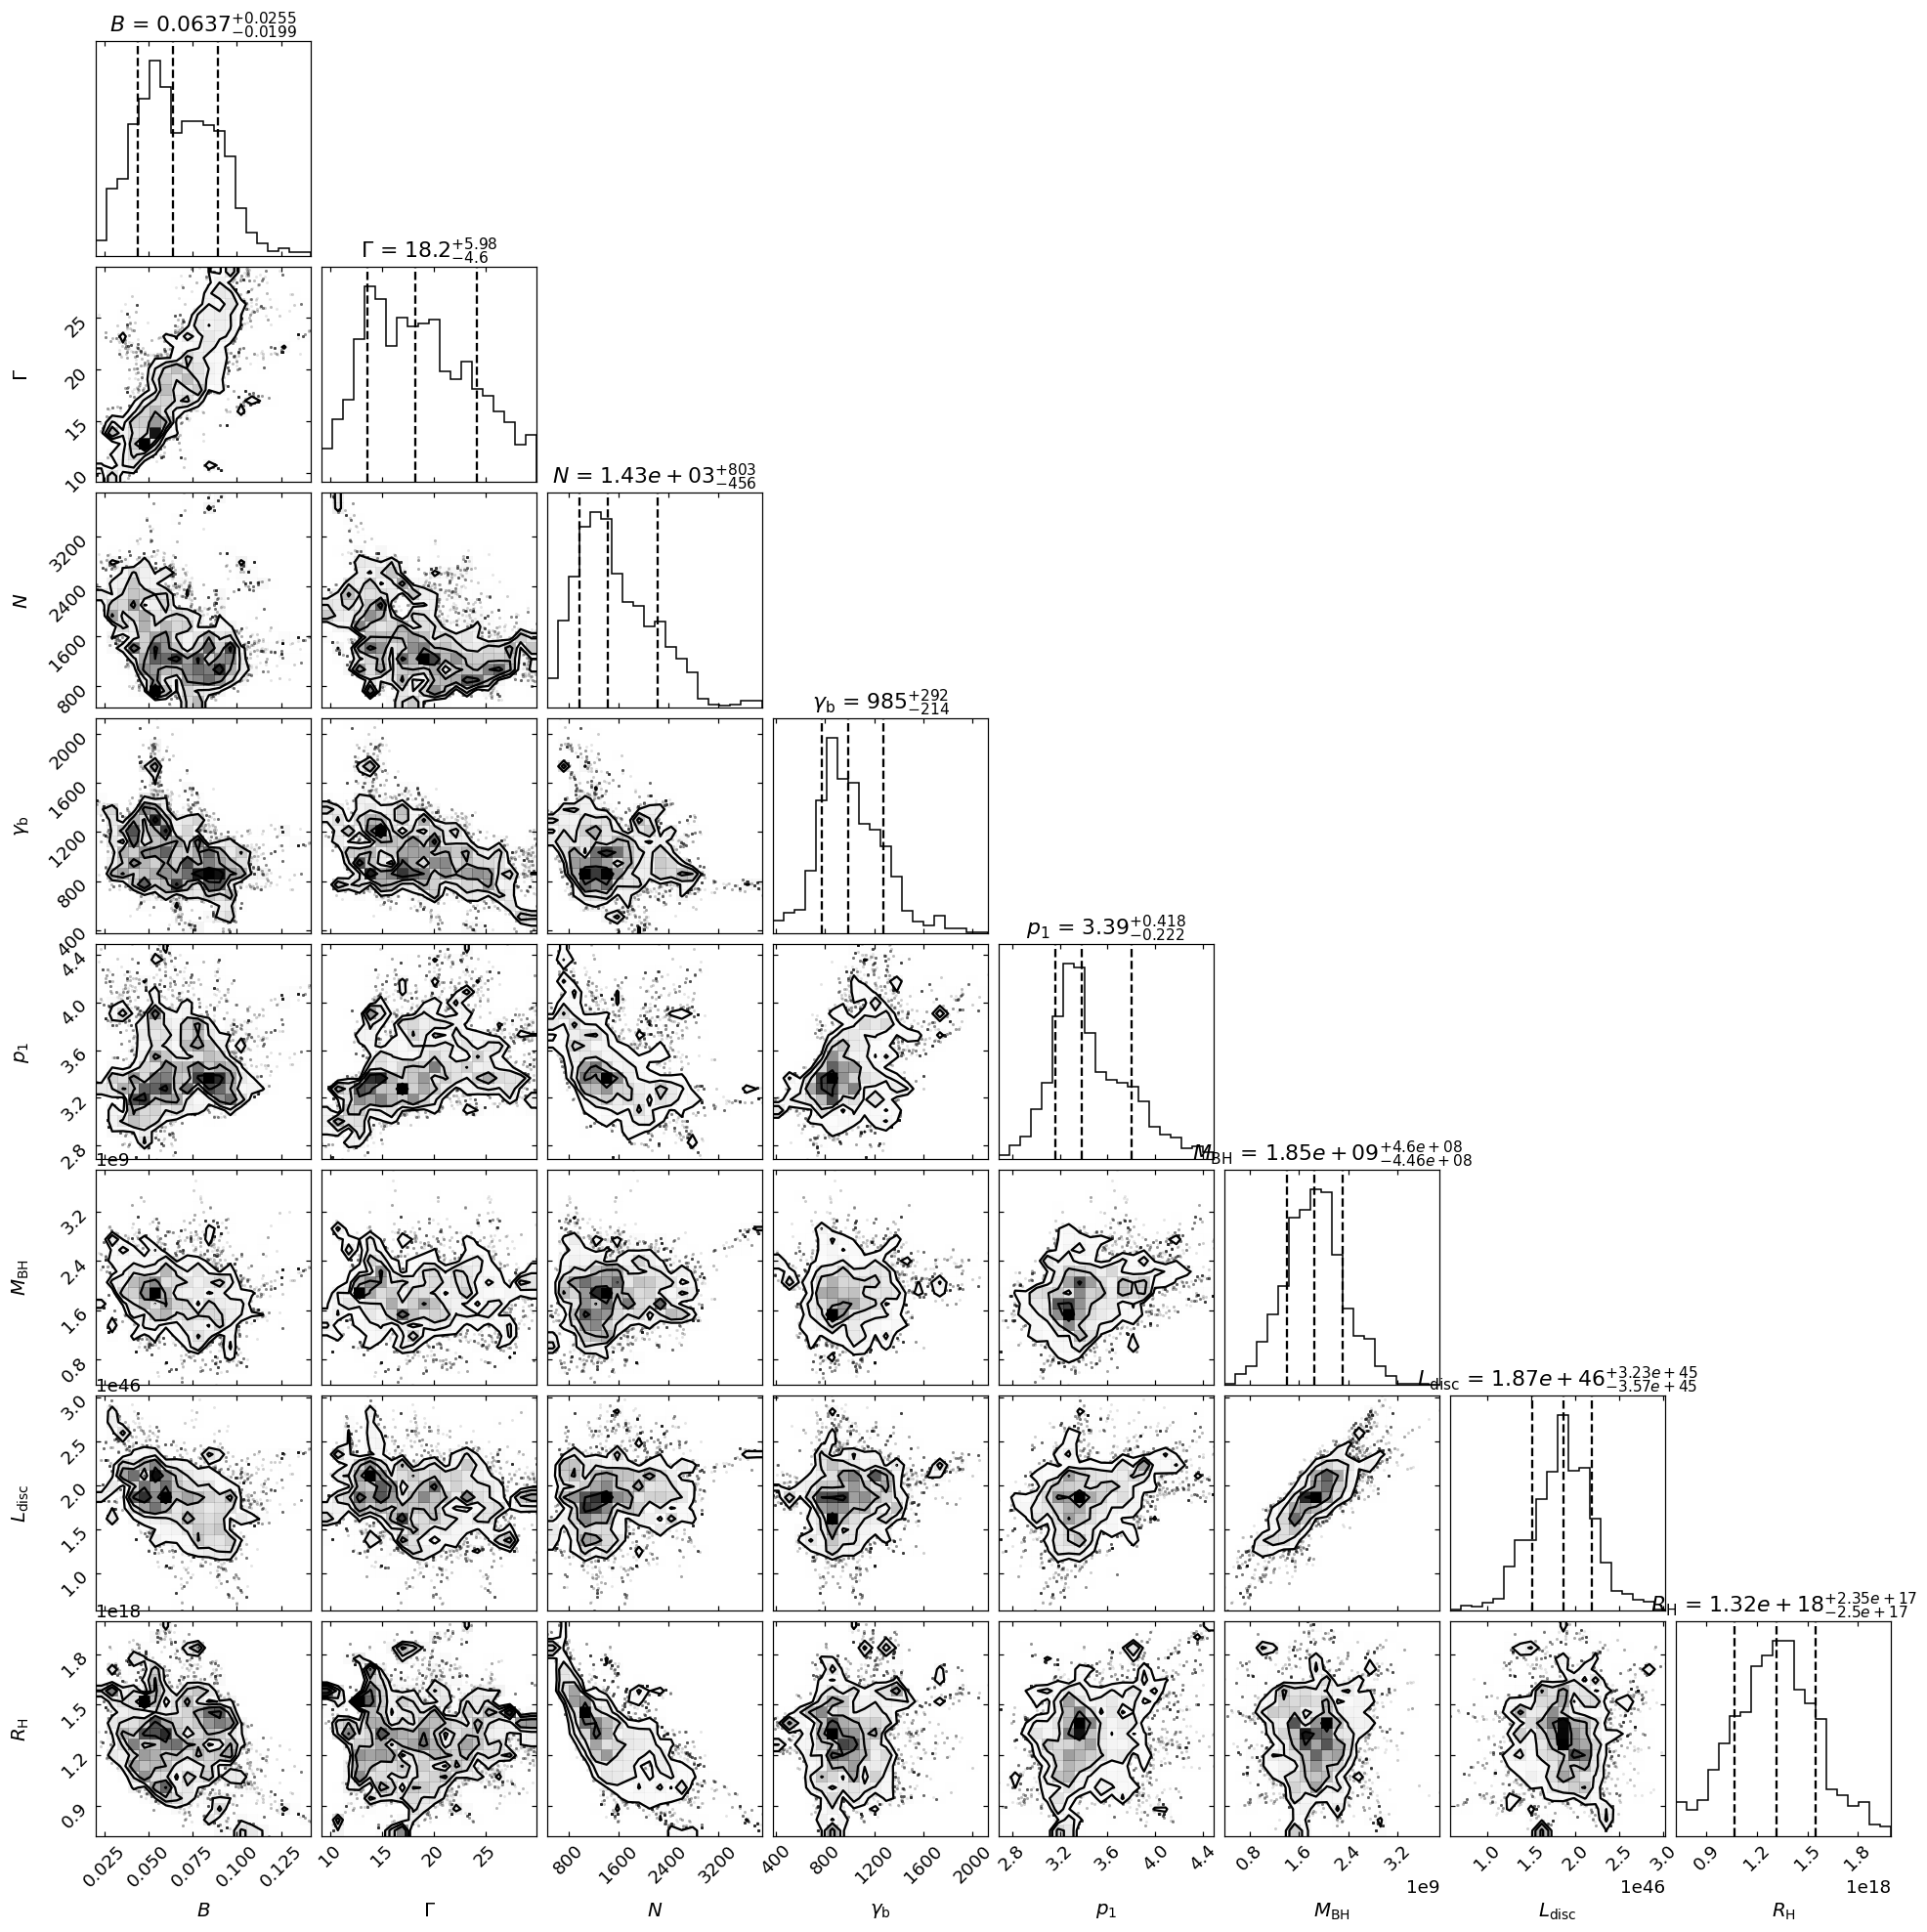

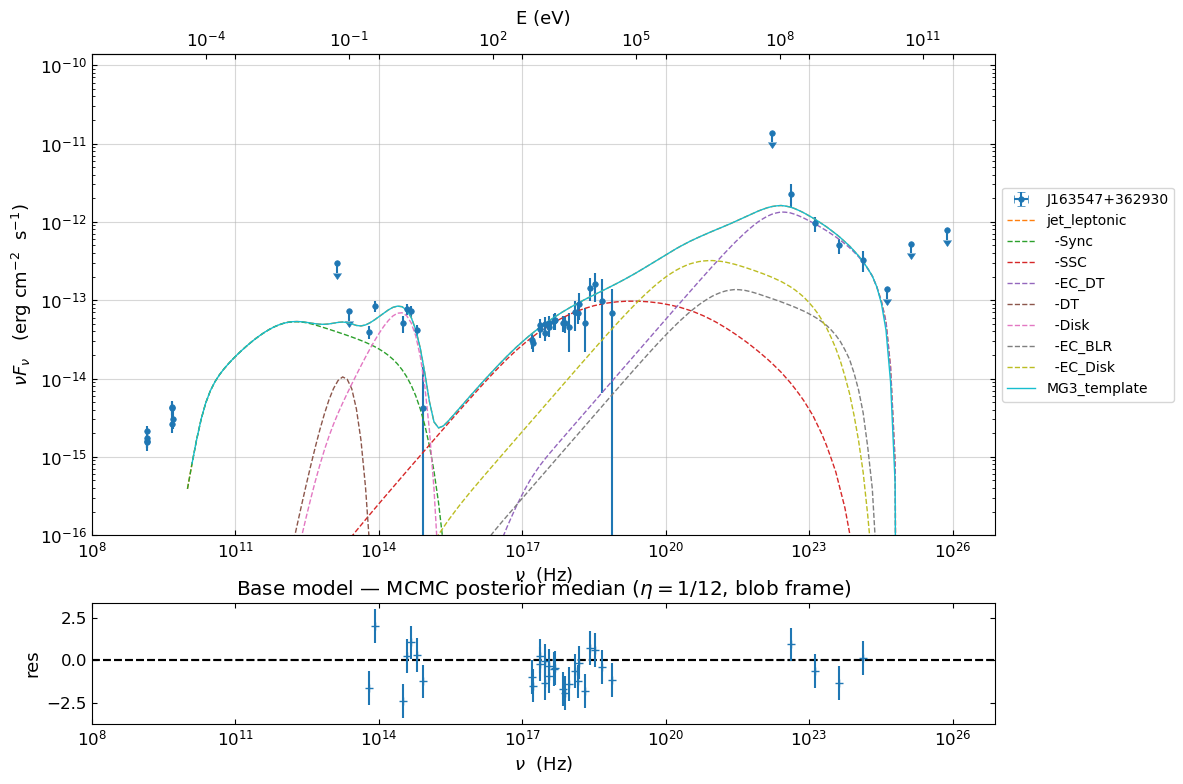

In [4]:
import pandas as pd
import corner

model_tag = 'base_eta0p083'

# 1. load the Minuit result (model, minimizer, bounds)
fit_model = FitModel.load_model(f'Model_Minuit_{model_tag}.pkl')
fit_model.jet_leptonic.set_external_field_transf(EXT_FIELD_FRAME)
model_minimizer = ModelMinimizer.load_model(f'Minimizer_{model_tag}.pkl')
with open(f'bounds_{model_tag}.json') as f:
    bounds = json.load(f)

# 2. parameters to sample (the others stay at the Minuit values)
sampled_params = ['B', 'BulkFactor', 'N', 'gamma_break', 'p_1',   # jet
                  'M_BH', 'L_Disk',                               # disc
                  'R_H']                                          # blob position
bounds_mcmc = {pname: bounds[pname] for pname in sampled_params}

print("Fixed at the Minuit best fit:")
for pname in ['T_DT', 'R_inner_Sw', 'R_ext_Sw', 'p', 'gmin', 'gmax']:
    print(f"   {pname:>11s} = {fit_model.jet_leptonic.parameters.get_par_by_name(pname).val:.4e}")

# 3. run the sampler
nwalkers = 32          # >= 2 x number of sampled parameters
nsteps   = 800
burnin   = 300

if RUN_MCMC:
    mcmc = McmcSampler(model_minimizer)
    mcmc.model.jet_leptonic.set_external_field_transf(EXT_FIELD_FRAME)
    mcmc.model.jet_leptonic.set_num_c_threads(8)

    mcmc.set_labels(use_labels_dict={'jet_leptonic': sampled_params})
    mcmc.set_bounds()                                               # builds the internal list...
    mcmc._bounds = [list(bounds_mcmc[p]) for p in mcmc.labels]      # ...then use our flat-prior box
    print("Sampled:", mcmc.labels)

    mcmc.run_sampler(nwalkers=nwalkers,
                     burnin=burnin,
                     steps=nsteps,
                     walker_start_bound=0.05,     # walkers start within ~5% of the Minuit values
                     progress='notebook')

    mcmc.save(f'mcmc_{model_tag}.pkl')

    # Save the chain in a plain numpy file as well (safe to reload later)
    flat_samples = mcmc.sampler.get_chain(discard=burnin, flat=True)
    np.savez(f'chain_{model_tag}.npz',
             samples=flat_samples,
             chain=mcmc.sampler.get_chain(),
             labels=np.array(sampled_params),
             burnin=burnin)

d = np.load(f'chain_{model_tag}.npz')
flat_samples = d['samples']
chain = d['chain']

# 4. convergence diagnostics (from the saved chain)
from emcee.autocorr import integrated_time
acc = np.any(chain[1:] != chain[:-1], axis=2).mean()      # fraction of steps where a walker moved
tau = integrated_time(chain[burnin:], tol=0)
print(f"\nAcceptance fraction: {acc:.3f}   (healthy: 0.2-0.5)")
print(f"Steps after burn-in: {nsteps - burnin}")
for pname, t in zip(sampled_params, tau):
    print(f"   tau({pname:>11s}) = {t:6.1f} steps   ->  {(nsteps - burnin) / t:5.1f} autocorrelation times")

# 5. posterior table (median and 68% interval)
rows = []
for i, pname in enumerate(sampled_params):
    lo, med, hi = np.percentile(flat_samples[:, i], [16, 50, 84])
    rows.append({'Parameter': pname, 'Median': f"{med:.3e}",
                 '-1 sigma': f"{med - lo:.2e}", '+1 sigma': f"{hi - med:.2e}"})
print("\n=== MCMC posterior (eta = 1/12, blob frame) ===")
print(pd.DataFrame(rows).to_string(index=False))

# Warn if a posterior presses against its prior edge
for i, pname in enumerate(sampled_params):
    lo, hi = bounds_mcmc[pname]
    q16, q84 = np.percentile(flat_samples[:, i], [16, 84])
    if q16 < lo + 0.05 * (hi - lo) or q84 > hi - 0.05 * (hi - lo):
        print(f"WARNING: {pname} posterior presses against its bound [{lo}, {hi}]")

# 6. derived quantities
M_s  = flat_samples[:, sampled_params.index('M_BH')]
L_s  = flat_samples[:, sampled_params.index('L_Disk')]
RH_s = flat_samples[:, sampled_params.index('R_H')]
R_BLR_out_s = 1.1 * 3e17 * np.sqrt(L_s / 1e46)
R_DT_s      = 2e19 * np.sqrt(L_s / 1e46)

derived = {
    'lambda = L_disc / L_Edd': L_s / (1.26e38 * M_s),
    'Mdot [M_sun/yr]':         L_s / (ETA_BASE * (2.998e10)**2) / 1.989e33 * 3.156e7,
    'R_H / R_BLR_out':         RH_s / R_BLR_out_s,
    'R_H / R_DT':              RH_s / R_DT_s,
}
print("\nDerived:")
for name, arr in derived.items():
    lo, med, hi = np.percentile(arr, [16, 50, 84])
    print(f"   {name:>24s} = {med:.3e}  -{med - lo:.2e} +{hi - med:.2e}")

# 7. corner plot
labels_tex = [r'$B$', r'$\Gamma$', r'$N$', r'$\gamma_{\rm b}$', r'$p_1$',
              r'$M_{\rm BH}$', r'$L_{\rm disc}$', r'$R_{\rm H}$']
fig = corner.corner(flat_samples, labels=labels_tex,
                    quantiles=[0.16, 0.5, 0.84], show_titles=True, title_fmt='.3g')
plt.savefig(os.path.join(FIG_DIR, f'corner_{model_tag}.png'))
plt.show()

# 8. SED at the posterior median
for i, pname in enumerate(sampled_params):
    fit_model.jet_leptonic.parameters.get_par_by_name(pname).val = np.median(flat_samples[:, i])
fit_model.jet_leptonic.eval()
fit_model.eval()

p = fit_model.plot_model(sed_data=sed_data)
p.setlim(y_min=1e-16, x_min=1e8)
plt.title(r'Base model — MCMC posterior median ($\eta = 1/12$, blob frame)')
plt.savefig(os.path.join(FIG_DIR, f'SED_MCMC_median_{model_tag}.png'))
plt.show()